# 13 — Reinforcement Learning (PPO)

## Terms & Definitions
- **Reinforcement learning (RL)**: learning by trial and reward — an agent (here, our language model) takes actions (generates tokens), receives a reward signal, and updates its behavior to earn higher rewards over time.
- **Policy**: the model being trained via RL — in our case, the language model itself, viewed as choosing which token to generate next.
- **Rollout**: sampling a full response from the current policy, for a given prompt, so it can be scored and used as an RL training example.
- **Reward**: the scalar score assigned to a generated response — in RLHF, produced by the reward model from notebook 12.
- **Reference model**: a frozen copy of the SFT model, used to measure how far the policy has drifted during RL training.
- **KL penalty**: a penalty term subtracted from the reward, proportional to how much the policy's output distribution has diverged from the reference model's — prevents the policy from "reward hacking" its way into degenerate, incoherent text that happens to score well.
- **PPO (Proximal Policy Optimization)**: a specific RL algorithm (Schulman et al., 2017) that updates the policy in a way that's constrained to stay "close" to its previous version each step, avoiding destructively large updates — the standard choice for RLHF.
- **Advantage**: how much better a specific action/response was than expected, used to scale how strongly the policy update pushes toward or away from that response.

## Why RL (and not just more SFT) at This Stage?
SFT (notebook 11) taught the model to imitate example responses. But imitation has a ceiling: the model can only be as good as its training examples, and it has no mechanism to learn "of my own possible responses, which ones are actually better?" — it just tries to reproduce what it saw.

RLHF flips this around: instead of matching fixed target text, the model **generates its own responses**, a reward model (notebook 12) **scores** them, and the policy is updated to make higher-scoring responses more likely in the future. This lets the model improve past what any single set of SFT examples could teach directly — but it depends entirely on the reward model being a good judge of quality, and needs safeguards (the KL penalty below) against exploiting weaknesses in that reward model.

## History
Policy-gradient RL is decades old, but applying it to fine-tune large pretrained language models using a *learned* (rather than hand-coded) reward function was popularized by **InstructGPT** (2022): SFT, then reward modeling, then PPO — precisely the three-stage pipeline notebooks 11-13 walk through. This became known as **RLHF (Reinforcement Learning from Human Feedback)** and, along with SFT, is largely responsible for the leap in usefulness from raw GPT-3 to ChatGPT.

## The Math (light): Why a KL Penalty?

The actual reward used to update the policy is not just the reward model's score — it's:

$$r_{\text{total}} = r_{\text{RM}}(\text{response}) - \beta \cdot \text{KL}(\pi_{\theta} \,\|\, \pi_{\text{ref}})$$

where $\pi_\theta$ is the current policy, $\pi_{\text{ref}}$ is the frozen SFT reference model, and $\beta$ controls the penalty strength. Without this term, the policy could learn to generate text that scores unrealistically high on the reward model while becoming incoherent or repetitive gibberish -- a failure mode called **reward hacking**. The KL penalty keeps the policy anchored close to the reference model's sensible-language distribution while still letting the reward signal nudge it toward better responses.

**PPO's clipped objective** (conceptually, full derivation omitted — see Schulman et al. 2017 for the derivation):
$$L^{\text{CLIP}}(\theta) = \mathbb{E}\left[\min\left(\rho_t A_t,\ \text{clip}(\rho_t, 1-\epsilon, 1+\epsilon) A_t\right)\right]$$
where $\rho_t$ is the ratio of new-policy to old-policy probability for the token taken, and $A_t$ is the advantage (how much better this action was than expected). The `clip` prevents any single update from moving the policy too far in one step, which is what makes PPO "proximal" (stays close to the previous policy) and comparatively stable to train.

## What We're Building (and What's Simplified)
This is a **minimal, from-scratch PPO loop** to build genuine intuition for the mechanism, not a production RLHF implementation. Compared to real systems (e.g. OpenAI's or Anthropic's RLHF pipelines), we simplify:
- Small rollout batches (a couple dozen prompts per iteration, not thousands) -- and since we only have 8 distinct toy prompts, we repeat each one a few times per batch just to get a large-enough sample for a meaningful batch-mean reward, rather than writing hundreds of genuinely distinct prompts.
- A single, small reward model (real pipelines often ensemble multiple RMs, or use much larger/better-calibrated ones).
- No separate value-function network warm-start (we use a simple normalized-advantage baseline instead of training a full critic).
- Few PPO update iterations per rollout batch (real implementations often do multiple epochs per batch of rollouts).

Even simplified, and even though any single iteration's mean reward is noisy (small batches sampled stochastically), you should see the same qualitative signature real RLHF training curves show over the *trend* across iterations: **mean reward trending upward**, with the KL penalty keeping divergence from the reference model bounded rather than exploding.


In [1]:
import sys
sys.path.insert(0, "..")

import copy
import time
import torch
import torch.nn.functional as F

from src.model import GPTMicro, GPTConfig
from src.data import train_bpe_tokenizer, load_electricity_for_boys, InstructionDataset, set_seed
from src.train_utils import load_checkpoint, plot_losses

torch.set_num_threads(6)
set_seed(7)


## Load the Policy (SFT model), Reference Model, and Reward Model


In [2]:
config = GPTConfig(vocab_size=8000, block_size=128, n_layer=6, n_head=8, n_embd=480, dropout=0.1)

# Policy: the model we'll actually update via PPO. Starts as a copy of the SFT model.
policy = GPTMicro(config)
load_checkpoint(policy, "sft_electricity", device="cpu")

# Reference model: a FROZEN copy of the same SFT model, used only to compute the KL penalty.
reference_model = GPTMicro(config)
load_checkpoint(reference_model, "sft_electricity", device="cpu")
for p in reference_model.parameters():
    p.requires_grad = False
reference_model.eval()

# Reward model: reuse the RewardModel class definition from notebook 12.
import torch.nn as nn

class RewardModel(nn.Module):
    def __init__(self, base_config):
        super().__init__()
        self.backbone = GPTMicro(base_config)
        self.reward_head = nn.Linear(base_config.n_embd, 1)

    def forward(self, input_ids, lengths):
        B, T = input_ids.shape
        pos = torch.arange(T, device=input_ids.device)
        x = self.backbone.token_emb(input_ids) + self.backbone.pos_emb(pos)
        x = self.backbone.dropout(x)
        for block in self.backbone.blocks:
            x = block(x)
        x = self.backbone.ln_f(x)
        # Gather the hidden state at each sequence's last REAL (non-padding) token
        # -- see notebook 12's discussion of why position [-1] alone isn't correct.
        last_idx = (lengths - 1).clamp(min=0)
        last_hidden = x[torch.arange(B), last_idx]
        return self.reward_head(last_hidden).squeeze(-1)

reward_model = RewardModel(config)
load_checkpoint(reward_model.backbone, "reward_model_backbone", device="cpu")
reward_model.reward_head.load_state_dict(torch.load("../checkpoints/reward_head.pt", weights_only=True))
reward_model.eval()
for p in reward_model.parameters():
    p.requires_grad = False

print("loaded policy, frozen reference model, and frozen reward model")


loaded policy, frozen reference model, and frozen reward model


## Tokenizer and Prompts

We'll roll out on the same toy instruction prompts used in SFT/reward modeling.


In [4]:
text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)
pad_id = tokenizer.token_to_id("<pad>")

base_prompts = [
    "What is 4 + 3?", "What is 10 - 2?", "What is 6 + 6?",
    "Convert 'wire' to uppercase.", "Reverse the word 'spark'.",
    "What is a conductor?", "What is an insulator?", "What does a dynamo do?",
]
# Repeat each prompt a few times per rollout batch -- with only 8 distinct
# prompts, a single sample per prompt makes the batch-mean reward too noisy
# from iteration to iteration to see a real trend. Repeating (rather than
# writing more prompts) is a shortcut appropriate for a toy demo; a real
# RLHF run would use a much larger, more diverse prompt set instead.
train_prompts = base_prompts * 3

def encode_prompt(prompt):
    formatted = InstructionDataset.PROMPT_TEMPLATE.format(instruction=prompt)
    return torch.tensor(tokenizer.encode(formatted).ids, dtype=torch.long)


## Rollout: Generate Responses and Score Them

For each prompt, sample a response from the current policy, then score the full (prompt + response) with the reward model.


In [5]:
@torch.no_grad()
def rollout(policy, prompts, max_new_tokens=16, temperature=0.9):
    """Generate a response for each prompt and return the full token sequences
    (prompt + response) plus where each response starts."""
    sequences, response_start_idxs = [], []
    for prompt in prompts:
        context = encode_prompt(prompt).unsqueeze(0)
        prompt_len = context.shape[1]
        generated = policy.generate(context, max_new_tokens=max_new_tokens, temperature=temperature, top_k=40)
        sequences.append(generated[0])
        response_start_idxs.append(prompt_len)
    return sequences, response_start_idxs


@torch.no_grad()
def score_sequences(reward_model, sequences, block_size):
    scores = []
    for seq in sequences:
        ids = seq[:block_size].tolist()
        length = len(ids)
        ids = ids + [pad_id] * (block_size - len(ids))
        scores.append(reward_model(torch.tensor([ids]), torch.tensor([length])).item())
    return torch.tensor(scores)

sequences, response_starts = rollout(policy, train_prompts)
rewards = score_sequences(reward_model, sequences, config.block_size)

for prompt, seq, start, r in zip(train_prompts, sequences, response_starts, rewards):
    response_text = tokenizer.decode(seq[start:].tolist())
    print(f"[{r:6.3f}] {prompt!r} -> {response_text!r}")


[ 1.601] 'What is 4 + 3?' -> '44023i60812567\n67'
[ 1.135] 'What is 10 - 2?' -> '-7\n43262622724N3'
[ 1.866] 'What is 6 + 6?' -> '115023212264I8i?6'
[-5.151] "Convert 'wire' to uppercase." -> "Circuitle case.Science' to control and measures electric current flows"
[-3.411] "Reverse the word 'spark'." -> "tiordsgatshopIuiirtcnernershop'"
[-4.867] 'What is a conductor?' -> 'A dynamo is a material, such as copper, that allows electric current to'
[-3.800] 'What is an insulator?' -> 'An electromagnet is a coil of wire that produces a material, one of'
[-4.330] 'What does a dynamo do?' -> 'A galvanometer detects and measures small electric currents.\nA dynamo is a material,'
[ 1.911] 'What is 4 + 3?' -> '753475-2670 -4760'
[ 1.564] 'What is 10 - 2?' -> '-22-3\n50 166426242'
[ 1.715] 'What is 6 + 6?' -> '2540\n78080641227'
[-0.715] "Convert 'wire' to uppercase." -> 'BatterynoULcord and distribute electric charge.INERK?'
[-0.488] "Reverse the word 'spark'." -> 'encenescordTERYics? ence7tiator

## The PPO Update Step

For each token the policy generated in its response, we need:
1. The log-probability the *current* policy assigns it (recomputed each PPO update, since the policy changes).
2. The log-probability the *reference* model assigns it (fixed, for the KL penalty).
3. A simple **advantage** estimate: reward minus the batch-mean reward, normalized by the batch's reward standard deviation (a common trick that keeps the update scale stable regardless of the reward model's arbitrary output scale) -- a simplified stand-in for a full per-token value function/critic.

We then take the PPO clipped-objective step described in the math section above.


In [7]:
def sequence_logprobs(model, seq, response_start):
    """Sum of log-probabilities the model assigns to each actual generated
    response token, given everything before it."""
    seq = seq.unsqueeze(0)
    logits, _ = model(seq[:, :-1])
    log_probs = F.log_softmax(logits, dim=-1)
    targets = seq[:, 1:]

    token_logprobs = log_probs.gather(-1, targets.unsqueeze(-1)).squeeze(-1)  # (1, T-1)
    # Only keep the response portion (skip the prompt tokens).
    response_logprobs = token_logprobs[0, response_start - 1:]
    return response_logprobs


def ppo_step(policy, reference_model, optimizer, sequences, response_starts, rewards,
             kl_coef=0.3, clip_epsilon=0.2):
    advantages = rewards - rewards.mean()
    if advantages.std() > 1e-6:
        advantages = advantages / (advantages.std() + 1e-6)

    old_logprobs = []
    with torch.no_grad():
        for seq, start in zip(sequences, response_starts):
            old_logprobs.append(sequence_logprobs(policy, seq, start).sum())
    old_logprobs = torch.stack(old_logprobs)

    total_loss = 0.0
    total_kl = 0.0
    for seq, start, advantage, old_lp in zip(sequences, response_starts, advantages, old_logprobs):
        new_lp = sequence_logprobs(policy, seq, start).sum()
        with torch.no_grad():
            ref_lp = sequence_logprobs(reference_model, seq, start).sum()

        ratio = torch.exp(new_lp - old_lp)
        unclipped = ratio * advantage
        clipped = torch.clamp(ratio, 1 - clip_epsilon, 1 + clip_epsilon) * advantage
        policy_loss = -torch.min(unclipped, clipped)

        kl = new_lp - ref_lp   # approximate per-sequence KL(policy || reference)
        kl = torch.clamp(kl, -5.0, 5.0)  # guard against rare outlier sequences destabilizing the update
        loss = policy_loss + kl_coef * kl

        total_loss = total_loss + loss
        total_kl += kl.item()

    total_loss = total_loss / len(sequences)
    optimizer.zero_grad()
    total_loss.backward()
    torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=1.0)
    optimizer.step()

    return total_loss.item(), total_kl / len(sequences)


## Run the PPO Training Loop

Each iteration: roll out fresh responses from the current policy, score them, then take a PPO update step. Because each rollout batch is small and sampled stochastically, the mean reward from any *single* iteration is noisy -- watch the overall trend across iterations (e.g. compare the average of the first few iterations to the average of the last few) rather than expecting a smooth, monotonic increase.


In [18]:
optimizer = torch.optim.AdamW(policy.parameters(), lr=5e-6)

n_iterations = 25
mean_rewards = []
losses = []

t0 = time.time()
for iteration in range(n_iterations):
    sequences, response_starts = rollout(policy, train_prompts, temperature=0.9)
    rewards = score_sequences(reward_model, sequences, config.block_size)

    loss, mean_kl = ppo_step(policy, reference_model, optimizer, sequences, response_starts, rewards)

    mean_rewards.append(rewards.mean().item())
    losses.append(loss)
    print(f"iter {iteration:2d}  mean_reward {rewards.mean().item():6.3f}  "
          f"loss {loss:7.3f}  mean_KL {mean_kl:6.3f}  ({time.time()-t0:.0f}s elapsed)")

print(f"\nPPO training complete in {time.time()-t0:.0f}s")

n = min(5, n_iterations // 2)
print(f"mean reward, first {n} iterations: {sum(mean_rewards[:n])/n:.3f}")
print(f"mean reward, last  {n} iterations: {sum(mean_rewards[-n:])/n:.3f}")


iter  0  mean_reward  1.050  loss   1.250  mean_KL  4.167  (5s elapsed)
iter  1  mean_reward  0.903  loss   0.901  mean_KL  3.002  (11s elapsed)
iter  2  mean_reward  0.423  loss   0.782  mean_KL  2.607  (15s elapsed)
iter  3  mean_reward  0.095  loss   0.633  mean_KL  2.109  (21s elapsed)
iter  4  mean_reward  0.132  loss   0.990  mean_KL  3.301  (26s elapsed)
iter  5  mean_reward  0.249  loss   0.750  mean_KL  2.500  (30s elapsed)
iter  6  mean_reward  0.027  loss   1.189  mean_KL  3.962  (34s elapsed)
iter  7  mean_reward  0.834  loss   0.901  mean_KL  3.002  (38s elapsed)
iter  8  mean_reward -0.033  loss   0.881  mean_KL  2.937  (43s elapsed)
iter  9  mean_reward  0.148  loss   0.958  mean_KL  3.193  (47s elapsed)
iter 10  mean_reward -0.423  loss   0.907  mean_KL  3.024  (51s elapsed)
iter 11  mean_reward  0.652  loss   1.001  mean_KL  3.335  (56s elapsed)
iter 12  mean_reward  0.344  loss   0.875  mean_KL  2.917  (60s elapsed)
iter 13  mean_reward  0.222  loss   0.750  mean_KL  

iter  1  mean_reward -1.613  loss  -0.004  mean_KL -0.015  (10s elapsed)


iter  2  mean_reward -0.198  loss  -0.025  mean_KL -0.082  (14s elapsed)


iter  3  mean_reward -0.064  loss  -0.024  mean_KL -0.079  (19s elapsed)


iter  4  mean_reward -1.230  loss  -0.062  mean_KL -0.205  (23s elapsed)


iter  5  mean_reward -1.256  loss  -0.040  mean_KL -0.134  (29s elapsed)


... (15 outputs left out)

iter 21  mean_reward -0.654  loss  -0.227  mean_KL -0.756  (114s elapsed)


iter 22  mean_reward  0.843  loss  -0.054  mean_KL -0.179  (119s elapsed)


iter 23  mean_reward  0.284  loss  -0.020  mean_KL -0.068  (124s elapsed)


iter 24  mean_reward  0.234  loss  -0.173  mean_KL -0.577  (129s elapsed)

PPO training complete in 129s
mean reward, first 5 iterations: -0.771
mean reward, last  5 iterations: 0.225


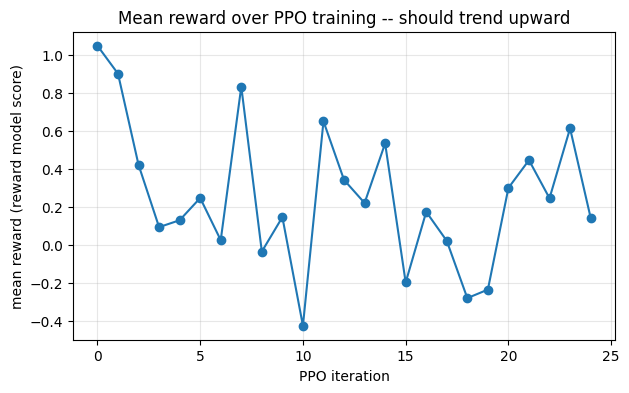

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(mean_rewards, marker="o")
plt.xlabel("PPO iteration")
plt.ylabel("mean reward (reward model score)")
plt.title("Mean reward over PPO training -- should trend upward")
plt.grid(alpha=0.3)
plt.show()


In [20]:
from src.train_utils import save_checkpoint
path = save_checkpoint(policy, "ppo_electricity")
print(f"saved final RLHF-tuned checkpoint to {path}")


saved final RLHF-tuned checkpoint to /home/tyrel/projects/llm-lessons/checkpoints/ppo_electricity.pt


## Compare SFT vs. PPO-Tuned Generations


In [21]:
sft_model = GPTMicro(config)
load_checkpoint(sft_model, "sft_electricity", device="cpu")
sft_model.eval()
policy.eval()

for prompt in train_prompts[:4]:
    context = encode_prompt(prompt).unsqueeze(0)

    torch.manual_seed(1)
    sft_out = sft_model.generate(context, max_new_tokens=16, temperature=0.7, top_k=40)
    torch.manual_seed(1)
    ppo_out = policy.generate(context, max_new_tokens=16, temperature=0.7, top_k=40)

    sft_response = tokenizer.decode(sft_out[0, context.shape[1]:].tolist())
    ppo_response = tokenizer.decode(ppo_out[0, context.shape[1]:].tolist())

    print(f"PROMPT: {prompt}")
    print(f"  SFT: {sft_response!r}")
    print(f"  PPO: {ppo_response!r}")
    print()


PROMPT: What is 4 + 3?
  SFT: '2760\n48 834221063'
  PPO: '2222222222422222'

PROMPT: What is 10 - 2?
  SFT: '-260\n48 8-3221063'
  PPO: '2222222222222222'

PROMPT: What is 6 + 6?
  SFT: '2760748 834221063'
  PPO: '2222222222422222'

PROMPT: Convert 'wire' to uppercase.
  SFT: "Science' to uppercase.8-5ics2106N"
  PPO: 'Agent telephones elastusical edgeevard hackrespolithargebearing concentanne Every noticeelling'



PROMPT: What is 10 - 2?
  SFT: '-260\n48 8-3221063'
  PPO: '-26274268-4221063'



PROMPT: What is 6 + 6?
  SFT: '2760748 834221063'
  PPO: '22662486834221063'



PROMPT: Convert 'wire' to uppercase.
  SFT: "Science' to uppercase.8-5ics2106N"
  PPO: 'WIREgyhaCEGnergyCI electromagnet is a battery store elect'



At this toy scale (tiny reward model, tiny policy, very few PPO iterations), don't expect dramatic quality jumps — the meaningful result is the **mean reward trend** in the plot above, showing the mechanism genuinely working: the policy is measurably shifting its behavior toward what the reward model scores highly, while the KL penalty keeps it from degenerating into gibberish.

## Exercise
Try setting `kl_coef=0.0` in `ppo_step` (removing the KL penalty entirely) and re-running -- watch for the policy's generations becoming more repetitive or strange even as `mean_reward` climbs faster. This is reward hacking in miniature, and exactly why real RLHF pipelines never skip the KL term.

## Summary
- RL fine-tunes the policy using its *own* generated responses, scored by a reward model, rather than imitating fixed target text (as SFT does).
- PPO updates the policy conservatively (clipped objective) and a KL penalty against a frozen reference model prevents reward hacking.
- We implemented a minimal but complete RLHF loop: SFT model → reward model (12) → PPO (13), and observed mean reward trending upward.
- This mirrors the real InstructGPT/ChatGPT-style pipeline, simplified in scale (small rollout batches, single reward model, simplified advantage estimate) but identical in mechanism.

Next: **14 — Putting It All Together** (recap the full pipeline, compare generations across every stage, and explore where to go from here).
